In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.io import loadmat


In [14]:
# Load Data
ATTRS = ["a1", "a2", "a3", "a4", "a5", "a6"]

def to_df(arr):
    return pd.DataFrame(np.asarray(arr), columns=ATTRS + ["class"]).astype(int)

def load_data(path):
    m = loadmat(path)
    keys = [k for k in m if not k.startswith("__")]
    out = {}
    for name in ["Data1", "Data2", "Data3"]:
        n = name.lower()
        train_key = next(k for k in keys if n in k.lower() and "train" in k.lower())
        test_key  = next(k for k in keys if n in k.lower() and "test" in k.lower())
        out[name] = (to_df(m[train_key]), to_df(m[test_key]))
    return out


In [5]:
# GINI calculations
def gini_of_labels(y):
    # computing GINI impurity
    y = np.asarray(y)
    if len(y) == 0:
      return 0
    _, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return 1.0 - sum(p ** 2)

def gini_index_for_attribute(X_col, y):
    # TODO: compute weighted GINI for one attribute
    X_col, y = np.asarray(X_col), np.asarray(y)
    n = len(X_col)

    if n == 0:
      return 0

    unique_vals = np.unique(X_col)
    gini_index = 0.0

    for v in unique_vals:
      mask = v == X_col

      # normalising the amount of times this attribute occurs in X_col
      weight = sum(mask) / n

      # for this particular attr, we find the gini using only output vals that
      # correspond to this attr
      gini_for_attr = gini_of_labels(y[mask])

      gini_index += weight * gini_for_attr

    return gini_index

def best_attribute(X, y, attr_names):
    # return best attribute based on GINI
    best_gini = float("inf")
    best_attr = None
    for attr in attr_names:
        gini = gini_index_for_attribute(X[attr].values, y)
        if gini < best_gini:
            best_gini = gini
            best_attr = attr
    return best_attr


In [6]:
# GINI table for Data1, Data2, Data3
def compute_gini_table(df_train):
    y = df_train["class"].values
    return pd.Series(
        {a: gini_index_for_attribute(df_train[a].values, y) for a in ATTRS}
    )

In [7]:
# Build Decision Tree
def build_tree(X_train, y_train):
    # develop decision tree using training data (recursive GINI partitioning)
    attr_names = list(X_train.columns)
    y = np.asarray(y_train)
    return _grow(X_train, y, attr_names, parent_majority=None)


def _grow(X, y, attr_names, parent_majority):
    # if this is an empty node, use the parent's most common class
    if len(y) == 0:
        return {"leaf": parent_majority}

    # most common class: count each class, take the one with the highest count
    classes, counts = np.unique(y, return_counts=True)
    majority = int(classes[np.argmax(counts)])

    # if all same class, or no questions left to ask, stop
    if len(classes) == 1 or len(attr_names) == 0:
        return {"leaf": majority}

    best = best_attribute(X, y, attr_names)

    # splitting doesn't make things purer so stop
    if gini_index_for_attribute(X[best].values, y) >= gini_of_labels(y) - 1e-12:
        return {"leaf": majority}

    node = {"attr": best, "children": {}, "majority": majority}
    remaining = [a for a in attr_names if a != best]
    for v in np.unique(X[best].values):
        mask = (X[best] == v).values
        node["children"][int(v)] = _grow(X[mask], y[mask], remaining, majority)
    return node


In [8]:
# Model Testing
def classify(model, X_test):
    # traverse the decision tree to classify samples
    preds = []
    for _, row in X_test.iterrows():
        node = model
        while "leaf" not in node:
            v = int(row[node["attr"]])
            if v not in node["children"]:
                preds.append(node["majority"])
                break
            node = node["children"][v]
        else:
            preds.append(node["leaf"])
    return np.array(preds)


In [9]:
# Test Accuracy of Decision Tree
def evaluate(y_true, y_pred):
    # compute accuracy
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))


In [10]:
import networkx as nx

def visualize_tree(tree):
    G = nx.DiGraph()
    labels = {}        # node id -> text shown in the node
    edge_labels = {}   # (parent, child) -> attribute value on the branch
    counter = [0]      # gives every node a unique id

    def add(node):
        nid = counter[0]
        counter[0] += 1
        if "leaf" in node:
            labels[nid] = f"class {node['leaf']}"
        else:
            labels[nid] = node["attr"]
        G.add_node(nid)
        if "children" in node:
            for v, child in node["children"].items():
                cid = add(child)
                G.add_edge(nid, cid)
                edge_labels[(nid, cid)] = v
        return nid

    add(tree)

    # layered layout: root at the top, each level one row lower
    depth = nx.single_source_shortest_path_length(G, 0)
    levels = {}
    for n, d in depth.items():
        levels.setdefault(d, []).append(n)
    pos = {}
    for d, nodes in levels.items():
        for i, n in enumerate(nodes):
            pos[n] = ((i + 1) / (len(nodes) + 1), -d)

    colors = ["lightgreen" if labels[n].startswith("class") else "lightblue" for n in G.nodes]
    plt.figure(figsize=(16, 8))
    nx.draw(G, pos, labels=labels, node_color=colors, node_size=1500, font_size=8, arrows=False)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)
    plt.title("Decision tree (Data1, GINI)")
    plt.show()

In [17]:
# Load Data (Data1, Data2, Data3)
data = load_data("DATASET.mat")     # {"Data1": (train_df, test_df), ...}


# compute and print the GINI table for all three datasets
table = pd.DataFrame(
    {name: compute_gini_table(train) for name, (train, _) in data.items()}
).T.round(4)
table["root"] = table[ATTRS].idxmin(axis=1)
display(table)



,a1,a2,a3,a4,a5,a6,root
Data1,0.1863,0.4935,0.4949,0.4620,0.4861,0.4664,a1
Data2,0.4928,0.4899,0.4885,0.4834,0.4900,0.4940,a4
Data3,0.4690,0.4639,0.4725,0.4447,0.4685,0.4691,a4


This is the table observed:

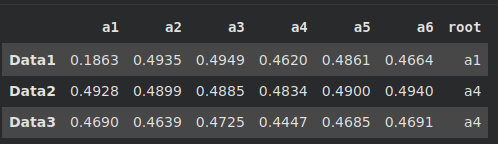

Root Attribute:

Data1: a1. It scores 0.1863, while every other attribute is above 0.46.
Data2: a4. It has the lowest score (0.4834).
Data3: a4. It has the lowest score (0.4447).

Is GINI a robust measure for difficult datasets?

No. GINI works well when one attribute is informative on its own, and it struggles when that is not true.

Data1: The rules are simple, so one attribute (a1) separates the classes far better than the rest. GINI finds it, and the tree reaches 100% test accuracy.
Data2: All six scores sit between 0.4834 and 0.4940, which is very close to 0.5, the worst possible GINI for two classes. No attribute helps on its own, because the class depends on a global count across attributes, not on any single one. GINI scores attributes one at a time, so it cannot observe that. The choice of a4 is essentially arbitrary, since the gap to the next attribute is about 0.005. A tree built this way will generalize poorly.
Data3: a4 stands out somewhat (0.4447 versus about 0.46 to 0.47 for the others), so GINI still gives a usable signal. But the scores are much closer to 0.5 than in Data1. The noisy labels blur the differences, so the choice is less reliable than on clean data.

GINI is a greedy, one-attribute-at-a-time measure. It is reliable when a single attribute carries the signal (Data1), weaker with noise (Data3), and unreliable when the pattern only shows up through combinations of attributes (Data2).

Data1 test accuracy: 1.0


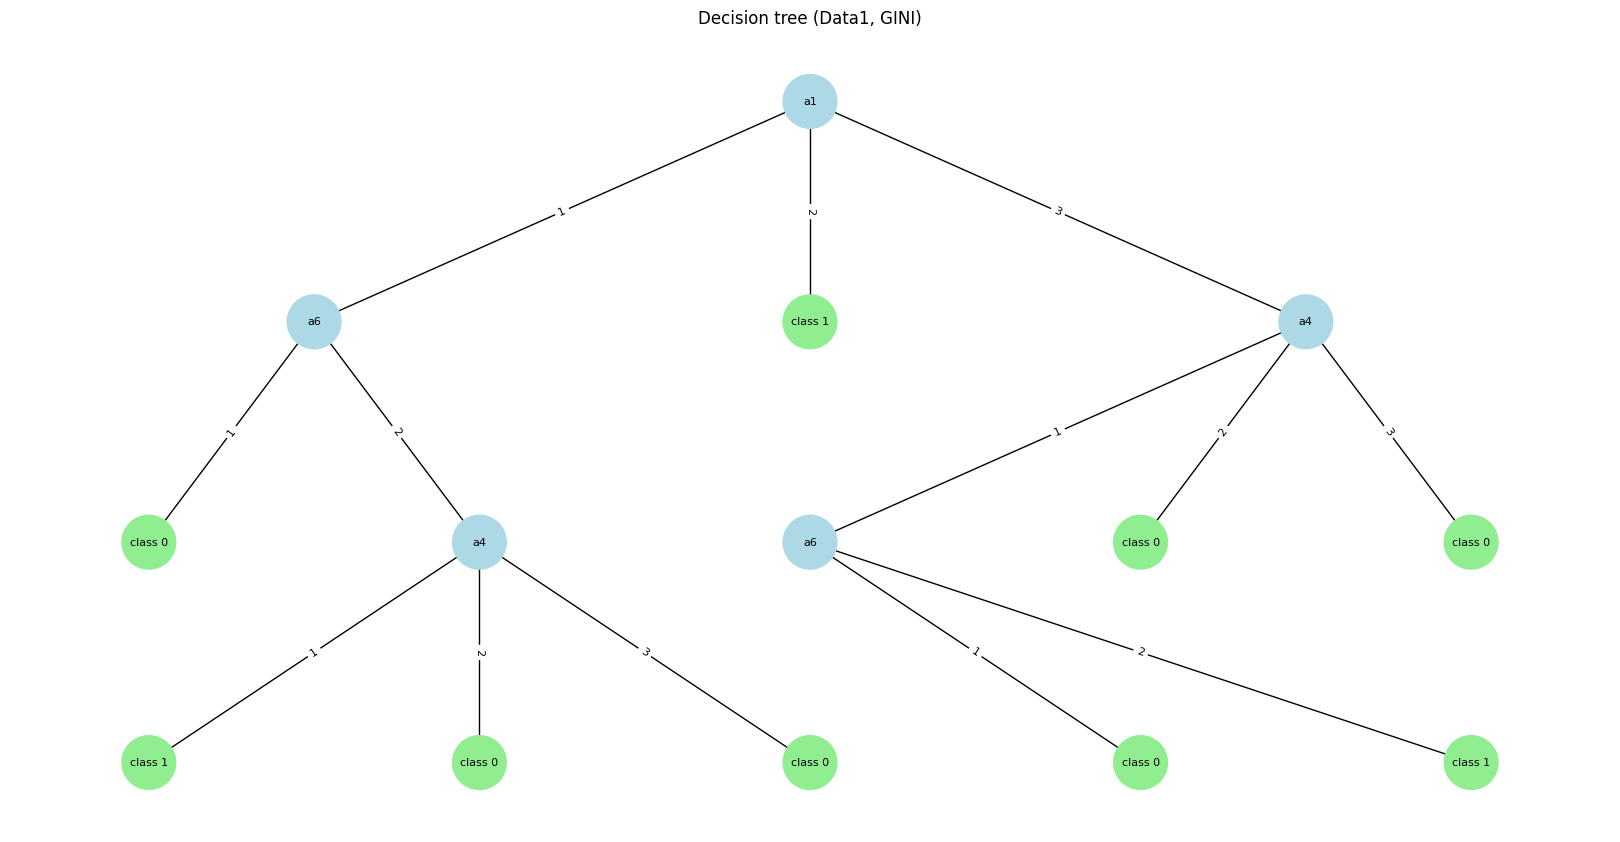

In [18]:


# Build Tree on Data1 training data
train1, test1 = data["Data1"]
tree = build_tree(train1[ATTRS], train1["class"].values)

# Classify Data1 test data
y_pred = classify(tree, test1[ATTRS])

# Evaluate Model
acc = evaluate(test1["class"].values, y_pred)
print("Data1 test accuracy:", acc)

# Visualize Tree
visualize_tree(tree)

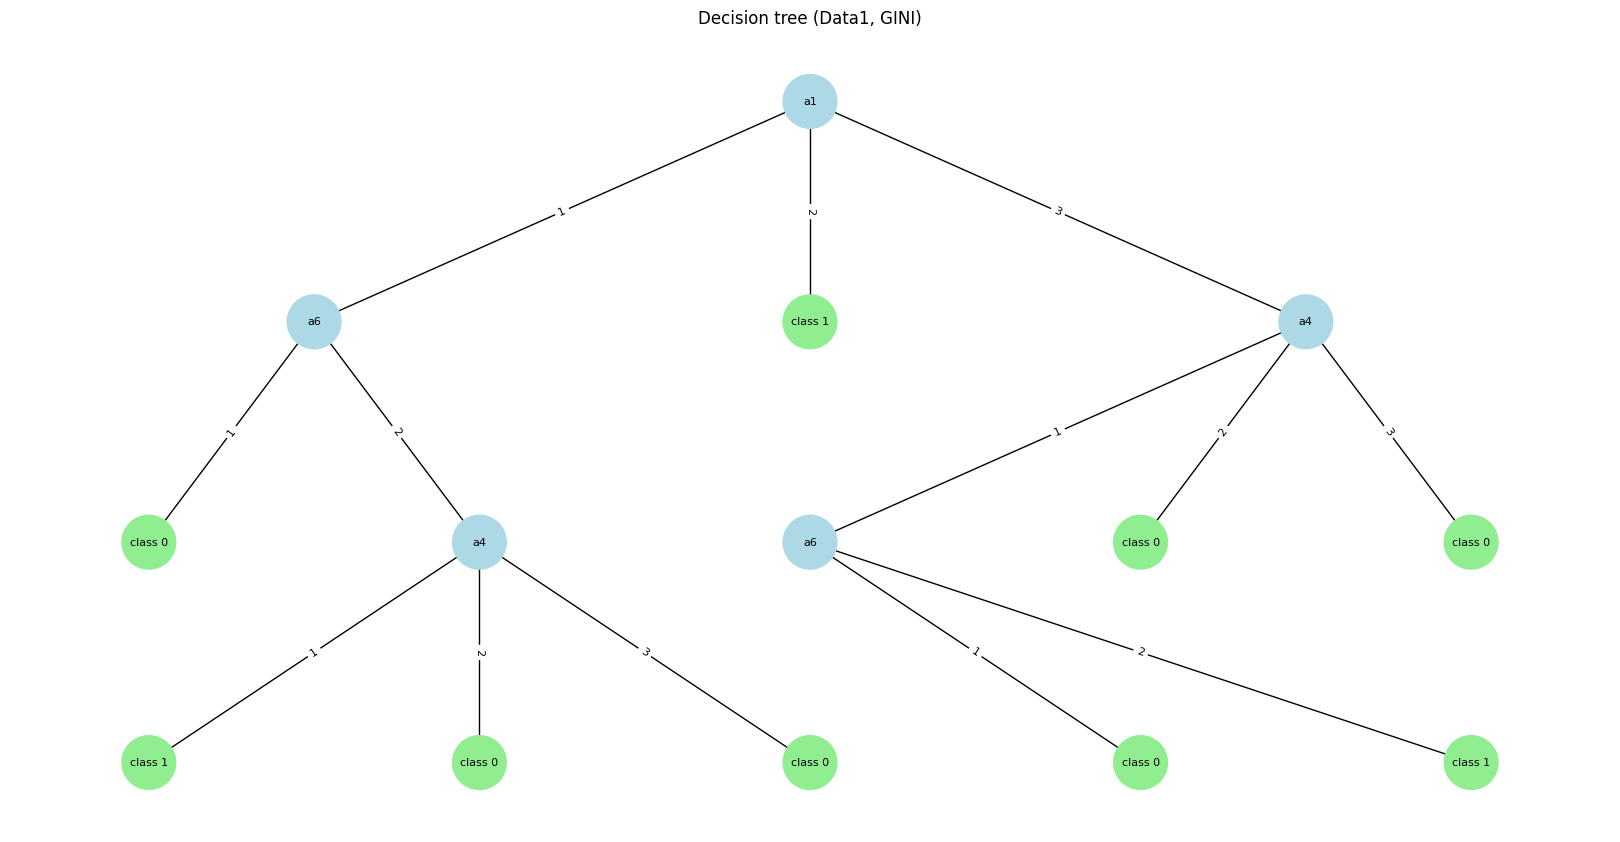